# HW1 — Statistical inference and supervised learning

**EE-411 — Fundamentals of Inference and Learning, 2026–2027**

**Learning objectives**
- Derive and compare estimators, quantify uncertainty, and interpret their limits.
- Fit and compare classifiers using cross-validation and a final test set.
- Diagnose class imbalance and apply resampling without leaking validation data.

**Prerequisites:** probability densities, likelihood, basic Bayesian inference, Fisher
information, classification, and Python/NumPy. Required packages are listed in
`requirements.txt`. Open this notebook with `HW1/` as the working directory.

**Working period:** approximately three weeks. The two parts are independent;
plan time for both mathematical reasoning and numerical experiments.

Submit your completed exercise notebook on Moodle by the announced deadline.
Each student submits their own work. AI tools may be used, but you are responsible
for checking and explaining every result. Briefly document how you used them.
Questions marked **optional** are extensions; the remaining questions form the core.

Put mathematical and written answers in the answer slots (you may use
`display(Markdown(r"..."))`), together with the requested code. Explain results;
tables or scores without interpretation are not complete answers. Run your
notebook from a fresh kernel before submitting it.

Use the supplied data; you do not need to download images or run the generators.
We use a fixed random seed (`SEED`) so that random operations give reproducible
results across runs. Setting `random_state=SEED` uses this fixed seed. A seed fixes
one realization, not a universal estimator or classifier ranking.

In [2]:
# PROVIDED: common imports and reproducibility settings.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 2203
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True})

## Part I — Statistical inference and estimation

Alex encodes the first two and last two digits of a phone code as parameters
$a$ and $b$. For $0<a<b$, consider the triangular density

$$p(x;a,b)=H(a,b)\begin{cases}
x/a,&0\leq x\leq a,\\
(b-x)/(b-a),&a<x\leq b,\\
0,&\text{otherwise}.
\end{cases}$$

We first treat the parameters as continuous. At the end, discuss the additional
constraint that a code consists of integer pairs. The files in this part reproduce
the current 2026 HW1 data. Do not inspect `generator.py` to obtain the answers.

### Question 1 — Normalization and expectation

Find $H(a,b)$ and derive the mean $\mu=\mathbb E[X]$. Show the integrals.

In [ ]:
# TODO: answer Question 1, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

#### 1. Find \(H(a,b)\)

Since \(p(x;a,b)\) is a probability density function, it must satisfy


$$\int_{-\infty}^{+\infty}p(x;a,b)\,dx=1$$


Therefore,

$$
H(a,b)\left(
\int_0^a\frac{x}{a}\,dx+
\int_a^b\frac{b-x}{b-a}\,dx
\right)=1
$$

Computing the two integrals we obtain,

$$
\int_0^a\frac{x}{a}\,dx
=\frac1a\left[\frac{x^2}{2}\right]_0^a
=\frac a2 $$

$$\int_a^b\frac{b-x}{b-a}\,dx
=\frac1{b-a}\left[bx-\frac{x^2}{2}\right]_a^b
=\frac{b-a}{2}
$$

Hence,

$$
H(a,b)\left(\frac a2+\frac{b-a}{2}\right)=1
$$

so

$$
H(a,b)\frac b2=1
$$

Thus, the normalization constant is

$$
\boxed{H(a,b)=\frac2b}
$$

#### 2. Derive the mean $\mu=\mathbb E[X]$

By definition,

$$
\mu=\mathbb E[X]
=\int_{-\infty}^{+\infty}x\,p(x;a,b)\,dx
$$

In our case we have,

$$
\mu=\frac2b\left(
\int_0^a\frac{x^2}{a}\,dx+
\int_a^b\frac{x(b-x)}{b-a}\,dx
\right)
$$

The first integral is

$$
\int_0^a\frac{x^2}{a}\,dx
=\frac1a\left[\frac{x^3}{3}\right]_0^a
=\frac{a^2}{3}
$$

The second integral is

$$
\int_a^b\frac{x(b-x)}{b-a}\,dx
=\frac1{b-a}\int_a^b(bx-x^2)\,dx
=\frac1{b-a}\left[\frac{bx^2}{2}-\frac{x^3}{3}\right]_a^b
=\frac{b^2+ab-2a^2}{6}
$$

Combining the results,

$$\
\mu
=\frac2b\left(
\frac{a^2}{3}+\frac{b^2+ab-2a^2}{6}
\right)
=\frac2b\cdot\frac{b^2+ab}{6}
=\frac{a+b}{3}
$$

Therefore, the mean is

$$
\boxed{\mathbb E[X]=\mu=\frac{a+b}{3}}
$$

### Question 2 — CDF, median, and mode

Derive the cumulative distribution function $F(t)=\Pr(X\leq t)$ and the median
$m$. Distinguish the cases $a\leq b/2$ and $a>b/2$. Compare the mean, median,
and mode, including the symmetric case.

In [ ]:
# TODO: answer Question 2, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

#### 1. Cumulative distribution function

The cumulative distribution function is defined by

$$
F(t)=P(X\leq t)=\int_{-\infty}^{t}p(x;a,b)\,dx.
$$

For $t<0$,

$$
F(t)=0.
$$

For $0\leq t\leq a$,

$$
F(t)
=\frac2b\int_0^t\frac{x}{a}\,dx
=\frac{2}{ab}\left[\frac{x^2}{2}\right]_0^t
=\frac{t^2}{ab}
$$

For $a<t\leq b$,

$$
F(t)
=\int_0^a p(x;a,b),dx+\int_a^t p(x;a,b),dx\
=\frac{a}{b}+\frac2b\int_a^t\frac{b-x}{b-a},dx
=\frac{a}{b}+\frac{2}{b(b-a)}
=\frac{a}{b}+\frac2b\int_a^t\frac{b-x}{b-a}\,dx
=\frac{a}{b}+\frac{2}{b(b-a)}
\left[bx-\frac{x^2}{2}\right]_a^t
=1-\frac{(b-t)^2}{b(b-a)}
$$

For $t>b$, 
$$F(t)=1$$

Therefore,

$$
F(t)=
\begin{cases}
0, & t<0,\\[4pt]
\dfrac{t^2}{ab}, & 0\leq t\leq a,\\[8pt]
1-\dfrac{(b-t)^2}{b(b-a)}, & a<t\leq b,\\[8pt]
1, & t>b.
\end{cases}
$$

#### 2. Median

The median $m$ satisfies $F(m)=1/2$.

**Case 1: $a\leq b/2$**

In this case, the median lies in the second interval, $a<m\leq b$. Thus,

$$
1-\frac{(b-m)^2}{b(b-a)}=\frac12
$$

Hence,

$$
(b-m)^2=\frac{b(b-a)}2
$$
$$
b-m=\sqrt{\frac{b(b-a)}2}
$$

Therefore,

$$
\boxed{m=b-\sqrt{\frac{b(b-a)}2}}
$$

**Case 2: $a>b/2$**

In this case, the median lies in the first interval, $0\leq m\leq a$. Thus,

$$
\frac{m^2}{ab}=\frac12
$$

Therefore,

$$
\boxed{m=\sqrt{\frac{ab}{2}}}
$$

#### 3. Mode and comparison with the mean and median

The density increases on $[0,a]$ and decreases on $[a,b]$. Its maximum occurs at $x=a$, so the mode is

$$
\operatorname{mode}=a
$$

From Question 1, the mean is

$$
\mu=\frac{a+b}{3}
$$

From question 2, the median is 
$$
m=
\begin{cases}
b-\sqrt{\dfrac{b(b-a)}{2}}, & a\leq \dfrac b2,\\[8pt]
\sqrt{\dfrac{ab}{2}}, & a>\dfrac b2.
\end{cases}
$$

Since $\mu-a=(b-2a)/3$, the mean is greater than, equal to, or less than the mode depending on whether $a<b/2$, $a=b/2$, or $a>b/2$. 
Thus, $\mu>a$ if $a<b/2$, $\mu=a$ if $a=b/2$, and $\mu<a$ if $a>b/2$.

To compare the median and the mode, we use $F(a)=a/b$. Since $F(m)=1/2$,

- If $a<b/2$, then $F(a)<1/2$, so $a<m$
- If $a=b/2$, then $F(a)=1/2$, so $a=m$
- If $a>b/2$, then $F(a)>1/2$, so $m<a$

Comparing the expressions for $m$ and $\mu$ gives the final ordering :

$$
\boxed{
\begin{cases}
a<m<\mu, & a<b/2,\\[4pt]
a=m=\mu=b/2, & a=b/2,\\[4pt]
\mu<m<a, & a>b/2.
\end{cases}
}
$$

When $a=b/2$, the density is symmetric about $b/2$, so the mean, median, and mode coincide.

### Question 3 — Implement the density and inspect the sample

For the file `fixed_b.npy`, $b=20$ is known. Implement `pdf(x, a, b=20)`.
Load the data, report its size, empirical mean and median, and plot a density
histogram with a density curve for an admissible $a$ of your choice.
Label the figure. Do not assume that your chosen plotting value is the true $a$.

Sample size: 100
Empirical mean: 10.739751742853539
Empirical median: 10.700494688840413


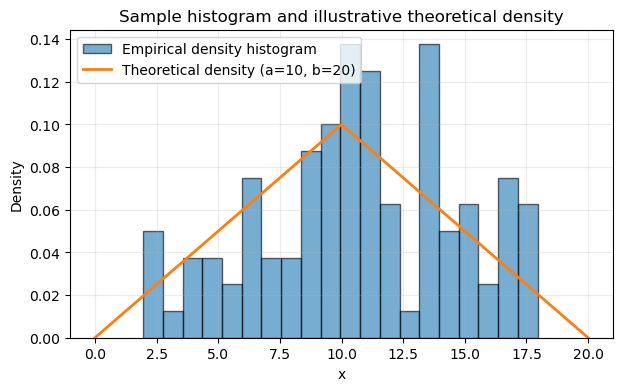

In [3]:
# TODO: answer Question 3, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

def pdf(x, a, b=20):
    x = np.asarray(x)
    return (2 / b) * np.where(
        (x >= 0) & (x <= a), x / a,
        np.where((x > a) & (x <= b), (b - x) / (b - a), 0)
    )

# Load the sample
data = np.load("fixed_b.npy")

# Report sample statistics
print("Sample size:", data.size)
print("Empirical mean:", np.mean(data))
print("Empirical median:", np.median(data))

# Plot density histogram and an illustrative density curve
b = 20
a_plot = 10  

x = np.linspace(0, b, 500)

plt.hist(data, bins=20, density=True, alpha=0.6,
         edgecolor="black", label="Empirical density histogram")
plt.plot(x, pdf(x, a_plot, b), linewidth=2,
         label=f"Theoretical density (a={a_plot}, b={b})")

plt.xlabel("x")
plt.ylabel("Density")
plt.title("Sample histogram and illustrative theoretical density")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Question 4 — Mean and median estimators

Invert the expressions for the population mean and median to derive
$\hat a_{\mathrm{mean}}$ and $\hat a_{\mathrm{median}}$. Implement them and
evaluate them on the sample. Can finite-sample estimates fall outside $(0,b)$?
Use the untruncated formulas in the later MSE comparison and explain this choice.

#### 1. Mean Estimator

The population mean of the triangular distribution is

$$
\mathbb{E}[X] = \frac{a+b}{3}
$$

Replacing the population mean with the sample mean $\bar{X}$ gives

$$
\bar{X} = \frac{a+b}{3}
$$

Solving for $a$, we obtain the mean-based estimator

$$
\boxed{\hat{a}_{\mathrm{mean}} = 3\bar{X} - b}
$$

#### 2. Median Estimator

The median is

$$
m =
\begin{cases}
\sqrt{\dfrac{ab}{2}}, & \text{if } a >\dfrac{b}{2} \\[6pt]
b-\sqrt{\dfrac{b(b-a)}{2}}, & \text{if } a  \leq \dfrac{b}{2}
\end{cases}
$$

Replacing the population median with the sample median $\tilde{X}$, we derive the estimator by inverting these expressions.

If $\tilde{X} > b/2$, then

$$
\tilde{X} = \sqrt{\frac{ab}{2}}
\quad \Longrightarrow \quad
\hat{a} = \frac{2\tilde{X}^{2}}{b}
$$

If $\tilde{X} \leq b/2$, then

$$
b-\tilde{X} = \sqrt{\frac{b(b-a)}{2}}
$$

which gives

$$
\hat{a} = b-\frac{2(b-\tilde{X})^{2}}{b}
$$

Therefore, the median-based estimator is

$$
\boxed{
\hat{a}_{\mathrm{median}} =
\begin{cases}
\dfrac{2\tilde{X}^{2}}{b}, & \text{if } \tilde{X} > \dfrac{b}{2} \\[8pt]
b-\dfrac{2(b-\tilde{X})^{2}}{b}, & \text{if } \tilde{X} \leq \dfrac{b}{2}
\end{cases}
}
$$

#### 3. Finite-Sample Estimates

The mean-based estimator is

$$
\hat a_{\mathrm{mean}}=3\bar X-b
$$

Since $0\leq \bar X\leq b$, this estimator can fall outside $(0,b)$ :

1. If $\bar X\leq b/3$, then $\hat a_{\mathrm{mean}}\leq 0$

2. If $\bar X\geq 2b/3$, then $\hat a_{\mathrm{mean}}\geq b$

Therefore, the mean-based estimator can produce estimates outside the parameter space.

The median-based estimator is

$$
\hat{a}_{\mathrm{median}} =
\begin{cases}
\dfrac{2\tilde{X}^{2}}{b}, & \text{if } \tilde{X} > \dfrac{b}{2} \\[8pt]
b-\dfrac{2(b-\tilde{X})^{2}}{b}, & \text{if } \tilde{X} \leq \dfrac{b}{2}
\end{cases}
$$

For observations in $[0,b]$, this estimator belongs to $[0,b]$, although it can equal $0$ or $b$ in extreme cases.

#### 4. Mean Squared Error Comparison

The mean squared error (MSE) of an estimator $\hat{a}$ is defined as

$$
\operatorname{MSE}(\hat{a})
= \mathbb{E}\left[(\hat{a}-a)^2\right]
$$

We use the untruncated estimators in the MSE comparison. Truncating estimates to the parameter space would define different estimators and could change their bias and mean squared error. Using the original formulas allows us to compare the estimators obtained directly by inverting the population mean and median.

In [4]:
# TODO: answer Question 4, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 
def estimate_a_mean(sample, b):
    return 3 * np.mean(sample) - b

def estimate_a_median(sample, b):
    m = np.median(sample)

    if m >= b / 2:
        return 2 * m**2 / b
    else:
        return b - 2 * (b - m)**2 / b

a_mean = estimate_a_mean(data, b)
a_median = estimate_a_median(data, b)

print("Mean estimator:", a_mean)
print("Median estimator:", a_median)

Mean estimator: 12.219255228560613
Median estimator: 11.450058658590189


### Question 5 — Likelihood and maximum likelihood

Write and plot the log-likelihood $\ell(a;x_1,\ldots,x_n)$ for known $b=20$.
Compute the maximum-likelihood estimate. Check the maximum over a grid or the
sample locations rather than trusting a single local optimizer.

For numerical endpoint handling, optimize over $[\varepsilon b,(1-\varepsilon)b]$
with $\varepsilon=10^{-8}$. Report if the solution reaches a numerical boundary.
Explain why the log-likelihood can have several local maxima.

#### Log-Likelihood Function

For an independent sample $x_1,\ldots,x_n$, the likelihood function is

$$
L(a;x_1,\ldots,x_n)=\prod_{i=1}^{n}p(x_i;a,b)
$$

The log-likelihood is therefore

$$
\ell(a;x_1,\ldots,x_n)
=\sum_{i=1}^{n}\log p(x_i;a,b)
$$

For known $b=20$, the density is

$$
p(x_i;a,20)=
\begin{cases}
\dfrac{x_i}{10a}, & 0\leq x_i\leq a\\[6pt]
\dfrac{20-x_i}{10(20-a)}, & a<x_i\leq20
\end{cases}
$$

Hence,

$$
\ell(a)=\sum_{i=1}^{n}\log p(x_i;a,20)
$$

The maximum likelihood estimate is defined as

$$
\hat{a}_{\mathrm{MLE}}
=\underset{a\in[\varepsilon b(1-\varepsilon)b]}
{\operatorname{arg\,max}}\
\ell(a),
$$

where $b=20$ and $\varepsilon=10^{-8}$.

Grid estimate: 11.3657999727
MLE: 11.3657959791
Maximum log-likelihood: -277.191325
Numerical boundary reached: False


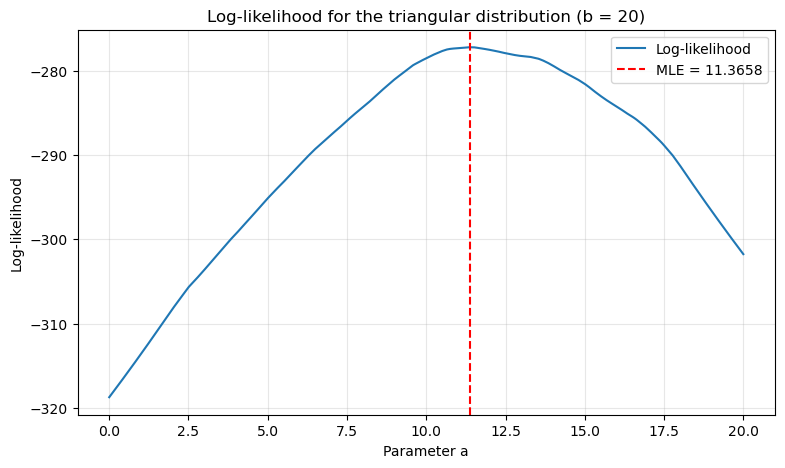

In [5]:
# TODO: answer Question 5, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 
b = 20
eps = 1e-8
a_min = eps * b
a_max = (1 - eps) * b

sample = np.asarray(data, dtype=float)

# Check that the observations belong to the support
if np.any((sample < 0) | (sample > b)):
    raise ValueError("All observations must belong to [0, b].")

if np.any((sample == 0) | (sample == b)):
    raise ValueError(
        "An observation at 0 or b gives zero likelihood "
        "under this density."
    )

def log_likelihood(a, x, b=20):
    if not (0 < a < b):
        return -np.inf

    x = np.asarray(x)

    # Log-density for each observation
    log_pdf = np.where(
        x <= a,
        np.log(2 / b) + np.log(x / a),
        np.log(2 / b) + np.log((b - x) / (b - a))
    )

    return np.sum(log_pdf)


# 1. Evaluate the log-likelihood on a dense grid
grid = np.linspace(a_min, a_max, 100_001)
ll_grid = np.array([
    log_likelihood(a, sample, b) for a in grid
])

a_grid = grid[np.argmax(ll_grid)]
ll_grid_max = np.max(ll_grid)

# 2. Also evaluate it at the sample locations
sample_candidates = sample[
    (sample >= a_min) & (sample <= a_max)
]

candidates = np.unique(np.concatenate([
    [a_min, a_max],
    sample_candidates,
    [a_grid]
]))

ll_candidates = np.array([
    log_likelihood(a, sample, b) for a in candidates
])

best_idx = np.argmax(ll_candidates)
a_mle = candidates[best_idx]
ll_max = ll_candidates[best_idx]

# 3. Check whether the solution reaches a numerical boundary
boundary_tol = 1e-12 * b
at_boundary = (
    abs(a_mle - a_min) <= boundary_tol
    or abs(a_mle - a_max) <= boundary_tol
)

print(f"Grid estimate: {a_grid:.10f}")
print(f"MLE: {a_mle:.10f}")
print(f"Maximum log-likelihood: {ll_max:.6f}")
print(f"Numerical boundary reached: {at_boundary}")

# 4. Plot
plt.figure(figsize=(9, 5))
plt.plot(grid, ll_grid, label="Log-likelihood")
plt.axvline(
    a_mle, color="red", linestyle="--",
    label=f"MLE = {a_mle:.4f}"
)
plt.xlabel("Parameter a")
plt.ylabel("Log-likelihood")
plt.title("Log-likelihood for the triangular distribution (b = 20)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Results and Interpretation

We plot the log-likelihood as a function of $a$ and search for its maximum using a dense grid and the sample locations, rather than relying on a single local optimizer. 

For $b=20$, the maximum likelihood estimate is

$$
\hat{a}_{\mathrm{MLE}} \approx 11.3658.
$$

The corresponding maximum log-likelihood is

$$
\ell(\hat{a}_{\mathrm{MLE}}) \approx -277.1913.
$$

The numerical boundary check returns `False`. Therefore, the estimated maximum does not reach either endpoint of the optimization interval.


### Multiple local maxima

The log-likelihood can have several local maxima because its expression changes whenever $a$ crosses an observation $x_i$. Between consecutive observations, it is convex, since

$$
\ell''(a)=\frac{k}{a^2}+\frac{n-k}{(b-a)^2}\geq0,
$$

where $k$ is the number of observations satisfying $x_i\leq a$.

Therefore, local maxima can occur at sample locations or at the numerical boundaries. We check a dense grid and the sample locations to identify the global maximum rather than relying on a single local optimizer.

### Question 6 — Bootstrap uncertainty

Use 1,000 nonparametric bootstrap samples of size $n$ to compute percentile 95%
confidence intervals for the mean, median, and maximum-likelihood estimators.
Use the same bootstrap samples for the three estimators. Report the point estimates
and intervals. Explain the frequentist interpretation and whether a unique
integer value of $a$ is established.

In [ ]:
# TODO: answer Question 6, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

B = 1000
b = 20
eps = 1e-8

sample = np.asarray(data, dtype=float)
n = len(sample)

rng = np.random.default_rng(42)


def estimate_mle(x, b):
    lower = eps * b
    upper = (1 - eps) * b

    # The maximum can occur at a sample location or a boundary
    candidates = np.unique(np.concatenate((
        [lower, upper],
        x[(x >= lower) & (x <= upper)]
    )))

    A = candidates[:, None]
    X = x[None, :]

    log_pdf = np.where(
        X <= A,
        np.log(2 / b) + np.log(X / A),
        np.log(2 / b) + np.log((b - X) / (b - A))
    )

    log_likelihood = np.sum(log_pdf, axis=1)
    return candidates[np.argmax(log_likelihood)]

# Point estimates
point_mean = estimate_a_mean(sample, b)
point_median = estimate_a_median(sample, b)
point_mle = estimate_mle(sample, b)

# Bootstrap: use the same resampled data for all estimators
bootstrap_estimates = np.empty((B, 3))

for j in range(B):
    boot_sample = rng.choice(sample, size=n, replace=True)

    bootstrap_estimates[j, 0] = estimate_a_mean(boot_sample, b)
    bootstrap_estimates[j, 1] = estimate_a_median(boot_sample, b)
    bootstrap_estimates[j, 2] = estimate_mle(boot_sample, b)

# Percentile 95% confidence intervals
lower_ci = np.percentile(bootstrap_estimates, 2.5, axis=0)
upper_ci = np.percentile(bootstrap_estimates, 97.5, axis=0)

names = ["Mean", "Median", "MLE"]
point_estimates = [point_mean, point_median, point_mle]

print(f"Sample size: n = {n}")
print(f"Number of bootstrap samples: {B}\n")

for i, name in enumerate(names):
    print(
        f"{name:8s}: estimate = {point_estimates[i]:.4f}, "
        f"95% CI = [{lower_ci[i]:.4f}, {upper_ci[i]:.4f}]"
    )

Sample size: n = 100
Number of bootstrap samples: 1000

Mean    : estimate = 12.2193, 95% CI = [9.6901, 14.7796]
Median  : estimate = 11.4501, 95% CI = [9.9170, 13.2819]
MLE     : estimate = 11.3658, 95% CI = [9.7052, 13.9666]


#### Frequentist Interpretation

A 95% bootstrap confidence interval gives a range of plausible values for the unknown parameter $a$, based on the observed sample. It is constructed by repeatedly resampling the data and recalculating the estimator. A 95% confidence interval means that, over many repeated samples, approximately 95% of the confidence intervals constructed using this method would contain the true value of $a$. It does not mean that the fixed parameter has a 95% probability of belonging to the particular interval obtained from the data.

#### Is a unique integer value established ?

To determine whether the data support a unique integer value for $a$, we examine the integers contained in the confidence interval. The mean-based interval contains the integers 10, 11, 12, 13 and 14, while the median-based and MLE intervals each contain 10, 11, 12 and 13. Therefore, none of the three confidence intervals identifies a unique integer value for $a$.

Even if a confidence interval contained only one integer, this would not prove that the true parameter equals that integer.

### Question 7 — Fisher information and the Cramér–Rao bound

Compute the one-observation Fisher information
$I_1(a)=\mathbb E[(\partial_a\log p(X;a,b))^2]$ for fixed $b$ and interior $a$.
Deduce $I_n(a)$ and the Cramér–Rao variance bound for an unbiased estimator.
Which of the estimators above is known to be unbiased? Explain why the unbiased
bound must not be asserted as a finite-sample MSE bound for every estimator.

In [ ]:
# TODO: answer Question 7, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

#### 1. Fisher information for one-observation

For the triangular distribution with known $b$ and unknown $a\in(0,b)$, the probability density function is

$$
p(x;a,b)=
\begin{cases}
\dfrac{2x}{ab} & 0\leq x\leq a\\[6pt]
\dfrac{2(b-x)}{b(b-a)} & a<x\leq b\\[6pt]
0 & \text{otherwise}
\end{cases}
$$

The score function is

$$
S_a(x)=\frac{\partial}{\partial a}\log p(x;a,b)
=
\begin{cases}
-\dfrac{1}{a}, & x<a\\[6pt]
\dfrac{1}{b-a}, & x>a
\end{cases}
$$

Since

$$
P(X\leq a)=\frac{a}{b},
\qquad
P(X>a)=\frac{b-a}{b},
$$

the Fisher information for one observation is

$$
\begin{aligned}
I_1(a)
&=\mathbb{E}[S_a(X)^2]\\
&=\frac{a}{b}\frac{1}{a^2}
+\frac{b-a}{b}\frac{1}{(b-a)^2}\\
&=\boxed{\frac{1}{a(b-a)}}
\end{aligned}
$$

#### 2. Fisher information for $n$ observations

For an independent sample of size $n$, Fisher information is additive :

$$
\boxed{I_n(a)=nI_1(a)=\frac{n}{a(b-a)}}
$$

#### 3. Cramér–Rao variance bound for an unbiased estimator

For any unbiased estimator $\hat{a}$ satisfying the required regularity conditions, the Cramér–Rao inequality gives

$$
\operatorname{Var}(\hat{a})
\geq \frac{1}{I_n(a)}
$$

Therefore,

$$
\boxed{\operatorname{Var}(\hat{a})\geq\frac{a(b-a)}{n}}
$$

#### 4. Unbiased estimators

The mean-based estimator is unbiased because

$$
\begin{aligned}
\mathbb{E}[\hat{a}_{\mathrm{mean}}]
&=\mathbb{E}[3\bar{X}-b]\\
&=3\mathbb{E}[\bar{X}]-b\\
&=3\frac{a+b}{3}-b\\
&=a
\end{aligned}
$$

Thus,

$$
\boxed{\mathbb{E}[\hat{a}_{\mathrm{mean}}]=a}
$$

The median-based and maximum likelihood estimators are not generally known to be unbiased in finite samples.

#### 5. Why the unbiased bound is not a universal finite-sample MSE bound ?

The Cramér–Rao lower bound states that

$$
\operatorname{Var}(\hat{a})
\geq \frac{a(b-a)}{n}
$$

for unbiased estimators satisfying the required regularity conditions.

However, this inequality does not automatically apply to biased estimators. The mean squared error satisfies

$$
\operatorname{MSE}(\hat{a})
=
\operatorname{Var}(\hat{a})
+
\operatorname{Bias}(\hat{a})^2
$$

where

$$
\operatorname{Bias}(\hat{a})
=
\mathbb{E}[\hat{a}]-a
$$

For an unbiased estimator, the bias is zero, so its MSE equals its variance. For a biased estimator, however, the MSE depends on both its variance and its squared bias. Consequently, a biased estimator may have an MSE below the classical Cramér–Rao bound.

Therefore, the classical Cramér–Rao bound cannot be used as a universal finite-sample lower bound for the MSE of every estimator.

### Question 8 — Jeffreys prior and posterior estimation

Derive and normalize Jeffreys prior $\pi_J(a)\propto\sqrt{I_1(a)}$ on $(0,b)$.
Inspect the posterior density near the boundaries: does maximizing it define a
finite interior global MAP estimate? Distinguish MAP from maximum likelihood.

Instead, compute the posterior mean and an equal-tailed 95% credible interval
for `fixed_b.npy`. Numerical integration is sufficient. Hint: the substitution
$a=b\sin^2\theta$, $0<\theta<\pi/2$, removes the prior's integrable endpoint
singularities. Compare the interpretation with Question 6. Check numerical
stability by increasing your integration resolution.

#### 1. Jeffreys Prior

The Fisher information for one observation is

$$
I_1(a)=\frac{1}{a(b-a)}, \qquad 0<a<b
$$

Jeffreys prior is defined as

$$
\pi_J(a)\propto\sqrt{I_1(a)}
=\frac{1}{\sqrt{a(b-a)}}
$$

To normalize this prior, we search a constant C such that

$$
\int_0^b\frac{C}{\sqrt{a(b-a)}}da=1
$$

To do that, we use the substitution

$$
a=b\sin^2\theta,
\qquad 0<\theta<\frac{\pi}{2}
$$

Since

$$
da=2b\sin\theta\cos\theta\,d\theta,
$$

we obtain

$$
\int_0^b\frac{1}{\sqrt{a(b-a)}}\,da
=\int_0^{\pi/2}2\,d\theta
=\pi.
$$

Therefore, $C=1/\pi$ and the normalized Jeffreys prior is

$$
\boxed{
\pi_J(a)=\frac{1}{\pi\sqrt{a(b-a)}}
\qquad 0<a<b
}
$$

Although this density diverges at both endpoints, its singularities are integrable, so the prior is proper.

#### 2. Posterior density and MAP estimate

By Bayes' theorem, the posterior density is

$$
p(a\mid x_1,\ldots,x_n)
=
\frac{L(a)\pi_J(a)}
{\displaystyle\int_0^b L(u)\pi_J(u)\,du}
$$

For observations strictly between $0$ and $b$, the likelihood approaches a finite, positive limit as $a$ approaches either endpoint. However, Jeffreys prior diverges at both endpoints. Consequently,

$$
\lim_{a\to0^+}p(a\mid x)=+\infty
\qquad
\lim_{a\to b^-}p(a\mid x)=+\infty
$$

Thus, the posterior density is unbounded near the boundaries and does not reach a finite global maximum at an interior point. Therefore, a global interior MAP estimate is not defined.

The maximum likelihood estimator (MLE) maximizes the likelihood $L(a)$, whereas the maximum a posteriori (MAP) estimator maximizes the posterior density $L(a)\pi_J(a)$, up to a normalization constant. 

#### 3. Posterior Mean and 95% Credible Interval

Instead of using the MAP, we estimate $a$ using its posterior mean :

$$
\boxed{
\mathbb{E}[a\mid x]
=
\frac{\displaystyle\int_0^b aL(a)\pi_J(a)\,da}
{\displaystyle\int_0^b L(a)\pi_J(a)\,da}.
}
$$

The equal-tailed 95% credible interval $[a_{0.025},a_{0.975}]$ is defined by

$$
P(a\leq a_{0.025}\mid x)=0.025,
$$

and

$$
P(a\leq a_{0.975}\mid x)=0.975.
$$

Equivalently, 2.5% of the posterior probability lies below the interval and 2.5% lies above it.

To perform numerical integration, we use the substitution

$$
a=b\sin^2\theta,
\qquad 0<\theta<\frac{\pi}{2}.
$$

Under this transformation,

$$
\pi_J(a)\frac{da}{d\theta}=\frac{2}{\pi}.
$$

The prior's endpoint singularities are therefore removed in the transformed integration, making numerical computation more stable. We increase the integration resolution to check that the posterior mean and credible interval converge to stable values.

#### 4. Comparison with the Bootstrap interval

The bootstrap confidence interval from Question 6 is based on the sampling distribution of an estimator and has a frequentist interpretation: its coverage probability refers to repeated samples.

In contrast, the Bayesian credible interval contains 95% of the posterior probability for the parameter, conditional on the observed data and the chosen prior.

The two intervals express uncertainty differently and need not have identical endpoints.

In [11]:
# TODO: answer Question 8, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 
import numpy as np
from scipy.integrate import cumulative_trapezoid

# Load the sample
sample = np.asarray(np.load("fixed_b.npy"), dtype=float).ravel()
b = 20.0

if len(sample) == 0:
    raise ValueError("The sample is empty.")

if np.any(~np.isfinite(sample)) or np.any((sample <= 0) | (sample >= b)):
    raise ValueError("All observations must be strictly between 0 and b.")

# Log-likelihood for the standard triangular distribution
def log_likelihood(a, sample, b):
    if not 0 < a < b:
        return -np.inf

    left = sample <= a
    result = np.empty_like(sample)

    result[left] = (
        np.log(2 / b)
        + np.log(sample[left] / a)
    )

    result[~left] = (
        np.log(2 / b)
        + np.log((b - sample[~left]) / (b - a))
    )

    return np.sum(result)


def posterior_estimates(sample, b, N):
    # Midpoint-free trapezoidal integration on theta
    theta = np.linspace(0, np.pi / 2, N + 1)
    a = b * np.sin(theta)**2

    # Avoid evaluating the likelihood exactly at the boundaries
    a_safe = np.clip(a, 1e-12 * b, (1 - 1e-12) * b)

    logL = np.array([
        log_likelihood(ai, sample, b) for ai in a_safe
    ])

    # Stabilize exponentiation
    likelihood = np.exp(logL - np.max(logL))

    # Posterior density in theta is proportional to likelihood
    normalizer = np.trapz(likelihood, theta)
    density_theta = likelihood / normalizer

    # Transform back to obtain the posterior mean of a
    posterior_mean = np.trapz(
    a * density_theta, theta
    )

    # CDF in theta
    cdf = cumulative_trapezoid(
        density_theta, theta, initial=0
    )
    cdf /= cdf[-1]

    # Equal-tailed 95% credible interval
    theta_low = np.interp(0.025, cdf, theta)
    theta_high = np.interp(0.975, cdf, theta)

    a_low = b * np.sin(theta_low)**2
    a_high = b * np.sin(theta_high)**2

    return posterior_mean, a_low, a_high


# Check numerical stability at increasing resolutions
for N in [10_000, 50_000, 100_000, 200_000]:
    mean_a, ci_low, ci_high = posterior_estimates(
        sample, b, N
    )

    print(
        f"N = {N:>6}: "
        f"Posterior mean = {mean_a:.6f}, "
        f"95% credible interval = "
        f"[{ci_low:.6f}, {ci_high:.6f}]"
    )

N =  10000: Posterior mean = 11.649499, 95% credible interval = [9.740934, 13.947719]
N =  50000: Posterior mean = 11.649499, 95% credible interval = [9.740938, 13.947716]
N = 100000: Posterior mean = 11.649499, 95% credible interval = [9.740938, 13.947716]
N = 200000: Posterior mean = 11.649499, 95% credible interval = [9.740938, 13.947716]


### Question 9 — Sampling the distribution

Derive an inverse-CDF sampler from Question 2. Implement a vectorized function
`sample_triangular(a, b, size, rng)`, and check its empirical mean and histogram
using 10,000 samples with $a=13,b=20$. Explain why it avoids the repeated rejection
steps of a rejection sampler. Use only interior parameters $0<a<b$.

#### 1. Inverse-CDF sampling

The cumulative distribution function (CDF) of the triangular distribution with parameters $0<a<b$ is

$$
F(x)=
\begin{cases}
0 & x<0\\[4pt]
\dfrac{x^2}{ab} & 0\leq x\leq a\\[8pt]
1-\dfrac{(b-x)^2}{b(b-a)} & a<x\leq b\\[8pt]
1 & x>b
\end{cases}
$$

To generate random samples, let $U\sim\mathcal U(0,1)$. The inverse-CDF method sets $X=F^{-1}(U)$.

The CDF at the mode $a$ is

$$
F(a)=\frac{a}{b}
$$

Therefore, if $U\leq a/b$, we use the first branch :

$$
U=\frac{x^2}{ab}
\quad\Longrightarrow\quad
X=\sqrt{abU}
$$

Otherwise,

$$
U=1-\frac{(b-x)^2}{b(b-a)}
\quad\Longrightarrow\quad
X=b-\sqrt{b(b-a)(1-U)}.
$$

Thus, the inverse-CDF sampler is

$$
\boxed{
X=
\begin{cases}
\sqrt{abU} & U\leq a/b\\[5pt]
b-\sqrt{b(b-a)(1-U)} & U>a/b
\end{cases}
}
$$

#### 2. Theoretical validation

We generate 10,000 observations with $a=13$ and $b=20$, then compare their empirical mean and histogram with the theoretical distribution.

The theoretical mean is

$$
\mathbb E[X]=\frac{a+b}{3}
=\frac{13+20}{3}=11
$$

The histogram should approximate the triangular density, increasing linearly up to $a=13$ and decreasing linearly from $a=13$ to $b=20$.

#### 3. Why it avoids the repeated rejection steps of a rejection sampler ?

Inverse-CDF sampling transforms each uniform random variable into a valid observation using the inverse CDF. Every generated value is valid in $[0,b]$, so no samples need to be rejected. In contrast, rejection sampling may require several attempts to obtain one accepted observation. Therefore, inverse-CDF sampling is often more efficient when the inverse CDF is easy to compute.

Empirical mean:  10.9636
Theoretical mean: 11.0000


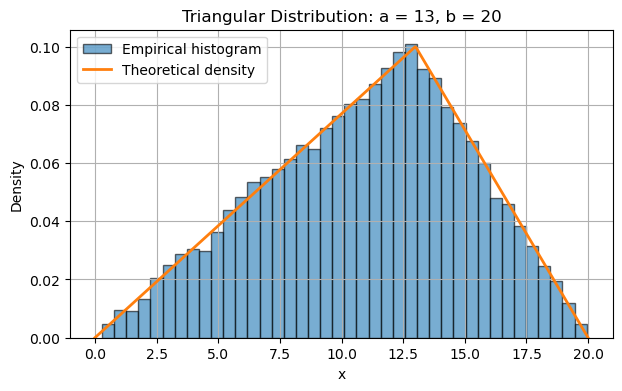

In [12]:
# TODO: answer Question 9, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

def sample_triangular(a, b, size, rng):
    if not (0 < a < b):
        raise ValueError("Parameters must satisfy 0 < a < b.")

    u = rng.uniform(0, 1, size=size)

    x = np.where(
        u <= a / b,
        np.sqrt(a * b * u),
        b - np.sqrt(b * (b - a) * (1 - u))
    )

    return x


# Generate 10,000 observations
a = 13
b = 20
n = 10_000
rng = np.random.default_rng(42)

sample = sample_triangular(a, b, n, rng)

# Compare empirical and theoretical means
empirical_mean = np.mean(sample)
theoretical_mean = (a + b) / 3

print(f"Empirical mean:  {empirical_mean:.4f}")
print(f"Theoretical mean: {theoretical_mean:.4f}")

# Plot empirical histogram and theoretical density
x = np.linspace(0, b, 500)

density = np.where(
    x <= a,
    2 * x / (a * b),
    2 * (b - x) / (b * (b - a))
)

plt.hist(
    sample,
    bins=40,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Empirical histogram"
)
plt.plot(x, density, linewidth=2, label="Theoretical density")

plt.xlabel("x")
plt.ylabel("Density")
plt.title("Triangular Distribution: a = 13, b = 20")
plt.legend()
plt.show()

### Question 10 — Compare the estimators in repeated experiments

Set $b=20$ and $n=1000$. For ten values of $a$ evenly spaced between 1 and 19,
repeat the experiment 300 times. On each sample compute the mean, median, MLE,
and Jeffreys posterior-mean estimates. Reuse the same sample for all estimators.
Plot estimated MSE with Monte Carlo standard errors, together with the unbiased
Cramér–Rao reference. Which estimators perform well, and does the answer depend
on $a$? Do not interpret a small Monte Carlo difference as a universal ranking.
For the posterior mean, 801 quadrature points are sufficient for this experiment;
check selected cases at higher resolution.

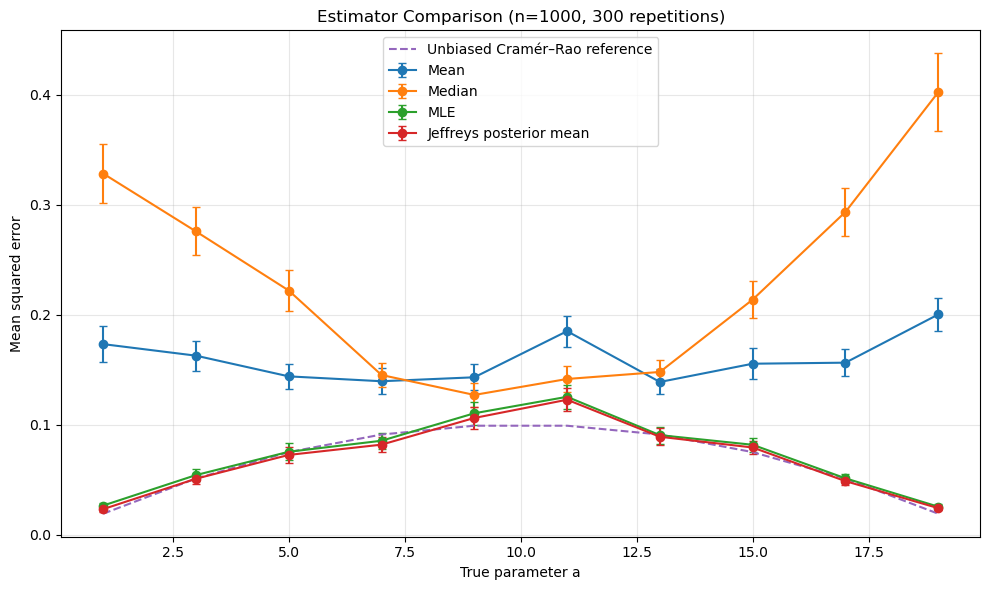

a                            Mean                     Median                        MLE    Jeffreys posterior mean
 1.0      0.173194 ± 0.016235    0.328288 ± 0.026831    0.026401 ± 0.002576    0.023157 ± 0.002165
 3.0      0.162698 ± 0.013511    0.275676 ± 0.021800    0.054109 ± 0.005088    0.050791 ± 0.004599
 5.0      0.143879 ± 0.011263    0.221934 ± 0.018453    0.075301 ± 0.007867    0.072453 ± 0.007336
 7.0      0.139443 ± 0.011951    0.145110 ± 0.011180    0.085340 ± 0.007282    0.081787 ± 0.006843
 9.0      0.143036 ± 0.011967    0.126993 ± 0.010944    0.110317 ± 0.010535    0.106050 ± 0.009957
11.0      0.184977 ± 0.014098    0.141500 ± 0.011981    0.125295 ± 0.010981    0.122638 ± 0.010438
13.0      0.138775 ± 0.011363    0.147882 ± 0.011133    0.090435 ± 0.007756    0.088962 ± 0.007563
15.0      0.155380 ± 0.014270    0.213699 ± 0.017059    0.081673 ± 0.006130    0.079207 ± 0.005994
17.0      0.156325 ± 0.012299    0.293389 ± 0.021823    0.051159 ± 0.004133    0.048613 ± 0.0

In [13]:
# TODO: answer Question 10, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# Parameters
b = 20.0
n = 1000
R = 300
a_values = np.linspace(1, 19, 10)
rng = np.random.default_rng(42)


# 1. Inverse-CDF sampling
def sample_triangular(a, b, size, rng):
    if not (0 < a < b):
        raise ValueError("Require 0 < a < b.")

    u = rng.uniform(size=size)
    return np.where(
        u <= a / b,
        np.sqrt(a * b * u),
        b - np.sqrt(b * (b - a) * (1 - u))
    )


# 2. Mean and median estimators
def estimate_mean(x, b):
    return 3 * np.mean(x) - b


def estimate_median(x, b):
    m = np.median(x)
    if m >= b / 2:
        return 2 * m**2 / b
    return b - 2 * (b - m)**2 / b


# 3. Log-likelihood for multiple candidate values of a
def loglikelihood_candidates(candidates, x, b):
    x_sorted = np.sort(x)
    log_x = np.log(x_sorted)
    log_bx = np.log(b - x_sorted)

    # Prefix sums and suffix sums
    prefix = np.concatenate(([0.0], np.cumsum(log_x)))
    suffix = np.concatenate((np.cumsum(log_bx[::-1])[::-1], [0.0]))

    k = np.searchsorted(x_sorted, candidates, side="right")
    k = np.clip(k, 0, len(x_sorted))

    return (
        len(x) * np.log(2 / b)
        + prefix[k]
        - k * np.log(candidates)
        + suffix[k]
        - (len(x) - k) * np.log(b - candidates)
    )


def estimate_mle(x, b):
    eps = 1e-10
    candidates = np.unique(np.concatenate((
        [eps * b, (1 - eps) * b],
        x[(x > eps * b) & (x < (1 - eps) * b)]
    )))
    logL = loglikelihood_candidates(candidates, x, b)
    return candidates[np.argmax(logL)]


# 4. Jeffreys posterior mean by midpoint quadrature in theta
def posterior_mean_jeffreys(x, b, N=801):
    theta = (np.arange(N) + 0.5) * (np.pi / 2 / N)
    a_grid = b * np.sin(theta)**2

    logL = loglikelihood_candidates(a_grid, x, b)

    # Stabilize exponentiation
    weights = np.exp(logL - np.max(logL))

    # The transformed Jeffreys prior is constant in theta,
    # so it cancels in the ratio defining the posterior mean.
    return np.sum(a_grid * weights) / np.sum(weights)


# 5. Repeated experiments
estimator_names = ["Mean", "Median", "MLE", "Jeffreys posterior mean"]
squared_errors = np.zeros((len(a_values), R, 4))

for i, a_true in enumerate(a_values):
    for r in range(R):
        # Reuse the same sample for all estimators
        x = sample_triangular(a_true, b, n, rng)

        estimates = [
            estimate_mean(x, b),
            estimate_median(x, b),
            estimate_mle(x, b),
            posterior_mean_jeffreys(x, b, N=801)
        ]

        squared_errors[i, r, :] = (
            np.asarray(estimates) - a_true
        )**2


# Monte Carlo MSE and its standard error
mse = np.mean(squared_errors, axis=1)
mc_se = np.std(squared_errors, axis=1, ddof=1) / np.sqrt(R)

crlb = a_values * (b - a_values) / n


# 6. Plot
plt.figure(figsize=(10, 6))

for j, name in enumerate(estimator_names):
    plt.errorbar(
        a_values, mse[:, j],
        yerr=mc_se[:, j],
        marker="o", capsize=3,
        label=name
    )

plt.plot(
    a_values, crlb, "--",
    label="Unbiased Cramér–Rao reference"
)

plt.xlabel("True parameter a")
plt.ylabel("Mean squared error")
plt.title("Estimator Comparison (n=1000, 300 repetitions)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 7. Numerical results
print("a       " + "  ".join(f"{name:>25}" for name in estimator_names))
for i, a_true in enumerate(a_values):
    values = "  ".join(
        f"{mse[i, j]:10.6f} ± {mc_se[i, j]:.6f}"
        for j in range(4)
    )
    print(f"{a_true:4.1f}    {values}")

print("\nCramér–Rao reference:")
for a_true, bound in zip(a_values, crlb):
    print(f"a={a_true:4.1f}: {bound:.6f}")


# 8. Check posterior quadrature resolution for selected cases
print("\nPosterior mean: quadrature stability")
for a_true in [1.0, 10.0, 19.0]:
    x = sample_triangular(a_true, b, n, rng)
    results = [
        posterior_mean_jeffreys(x, b, N)
        for N in [801, 1601, 3201]
    ]
    print(
        f"a={a_true:4.1f}: "
        f"801={results[0]:.6f}, "
        f"1601={results[1]:.6f}, "
        f"3201={results[2]:.6f}"
    )

#### Results and interpretation

Jeffreys prior is the best one.

Alex has changed the code. In the next questions, `full.npy` contains a new sample
with both $a$ and $b$ unknown. Neither parameter need equal the earlier value.
Continue treating parameters as continuous before discussing the integer code.

### Question 11 — Joint maximum-likelihood estimation

Load `full.npy`, report its size, and plot a density histogram. Estimate both
parameters by maximizing the likelihood under $0<a<b\le99$ and $b>\max_i x_i$.
Check numerical feasibility and compare several candidate values or starts.
Hint: for each fixed $b$, reuse the candidate-location method from Question 5,
then numerically maximize the resulting profile likelihood over $b$.

Sample size: n = 10000
Minimum observation: 0.531621
Maximum observation: 77.5001


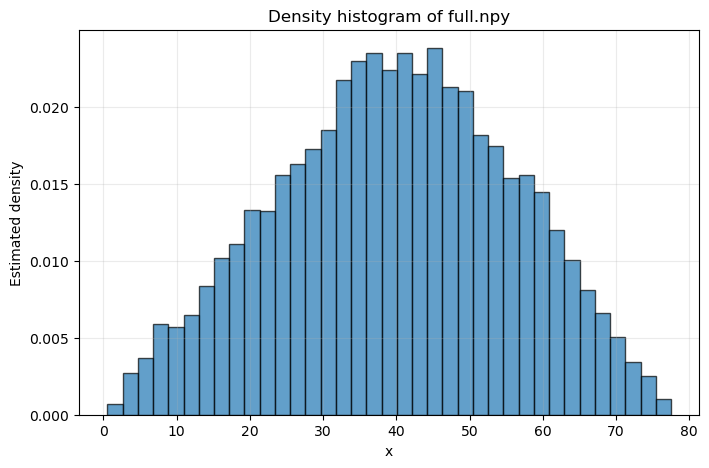

KeyboardInterrupt: 

In [14]:
# TODO: answer Question 11, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

from scipy.optimize import minimize_scalar

# Load the data
x = np.asarray(np.load("full.npy"), dtype=float).ravel()
x = x[np.isfinite(x)]

n = len(x)
xmin = np.min(x)
xmax = np.max(x)

print(f"Sample size: n = {n}")
print(f"Minimum observation: {xmin:.6g}")
print(f"Maximum observation: {xmax:.6g}")

if n == 0:
    raise ValueError("The sample is empty.")
if xmin < 0 or xmax >= 99:
    raise ValueError("The data are incompatible with 0 < a < b <= 99.")

# Density histogram
plt.figure(figsize=(8, 5))
plt.hist(x, bins="auto", density=True, edgecolor="black", alpha=0.7)
plt.xlabel("x")
plt.ylabel("Estimated density")
plt.title("Density histogram of full.npy")
plt.grid(alpha=0.25)
plt.show()


def log_likelihood(a, b, x):
    """Log-likelihood of the normalized triangular distribution."""
    if not (0 < a < b <= 99) or b <= np.max(x):
        return -np.inf

    left = x <= a
    right = ~left

    # All observations must lie in [0, b].
    if np.any(x < 0) or np.any(x >= b):
        return -np.inf

    result = len(x) * np.log(2.0 / b)

    if np.any(left):
        result += np.sum(np.log(x[left] / a))

    if np.any(right):
        result += np.sum(np.log((b - x[right]) / (b - a)))

    return result


def profile_a(b, x):
    """Maximize the likelihood over a for a fixed b."""
    if not (x.max() < b <= 99):
        return np.nan, -np.inf

    # Between consecutive observations, the log-likelihood
    # is convex in a, so its maximum occurs at an interval endpoint.
    candidates = np.unique(x[(x > 0) & (x < b)])

    # Include points close to the open boundaries as a numerical check.
    eps = 1e-10 * max(1.0, b)
    candidates = np.concatenate([
        candidates,
        [max(eps, np.nextafter(0.0, 1.0)),
         min(b - eps, np.nextafter(b, 0.0))]
    ])
    candidates = np.unique(candidates)
    candidates = candidates[(candidates > 0) & (candidates < b)]

    values = np.array([log_likelihood(a, b, x) for a in candidates])
    j = np.argmax(values)
    return candidates[j], values[j]


# Numerically maximize the profile likelihood over b.
# Use a grid first because the profile need not be unimodal.
b_lower = np.nextafter(xmax, np.inf)
b_grid = np.linspace(b_lower, 99.0, 2000)

profile_values = np.array([profile_a(b, x)[1] for b in b_grid])
best_grid_idx = np.argmax(profile_values)

# Refine around the best grid point.
left_idx = max(0, best_grid_idx - 2)
right_idx = min(len(b_grid) - 1, best_grid_idx + 2)
lo, hi = b_grid[left_idx], b_grid[right_idx]

candidates_b = [b_grid[best_grid_idx], 99.0]

if hi > lo:
    result = minimize_scalar(
        lambda b: -profile_a(b, x)[1],
        bounds=(lo, hi),
        method="bounded",
        options={"xatol": 1e-10}
    )
    candidates_b.append(result.x)

# Compare the refined solution, grid solution, and upper boundary.
solutions = []
for b in candidates_b:
    a, ll = profile_a(b, x)
    solutions.append((ll, a, b))

best_ll, a_hat, b_hat = max(solutions)

print("\nJoint maximum-likelihood estimates")
print(f"a_hat = {a_hat:.8f}")
print(f"b_hat = {b_hat:.8f}")
print(f"Maximum log-likelihood = {best_ll:.8f}")
print(f"Constraints satisfied: {0 < a_hat < b_hat <= 99 and b_hat > xmax}")

# Plot the profile log-likelihood
plt.figure(figsize=(8, 5))
plt.plot(b_grid, profile_values)
plt.axvline(b_hat, linestyle="--", label=f"Estimated b = {b_hat:.4f}")
plt.xlabel("b")
plt.ylabel("Profile log-likelihood")
plt.title("Profile log-likelihood for b")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# Compare several candidate solutions
print("\nCandidate solutions (log-likelihood, a, b):")
for ll, a, b in sorted(solutions, reverse=True):
    print(f"{ll:.8f}, {a:.8f}, {b:.8f}")

### Question 12 — Joint uncertainty and the code

Use 300 nonparametric bootstrap replicates to obtain marginal percentile 95%
intervals for $a$ and $b$ (you may increase this number). Display the bootstrap
estimates together in a scatter plot. Give a plausible integer code, list the
integer pairs inside the two marginal intervals, and explain why these intervals
do not guarantee unique or joint 95% recovery. Discuss the additional caution
needed when a parameter controls the support of a distribution.

In [15]:
# TODO: answer Question 12, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

from scipy.optimize import minimize_scalar

x = np.asarray(np.load("full.npy"), dtype=float).ravel()
x = x[np.isfinite(x)]

rng = np.random.default_rng(2026)
B = 300  # Number of bootstrap replicates


def log_likelihood(a, b, x):
    if not (0 < a < b <= 99 and b > np.max(x)):
        return -np.inf

    left = x <= a
    right = ~left

    if np.any(x <= 0):
        return -np.inf

    ll = len(x) * np.log(2 / b)
    ll += np.sum(np.log(x[left] / a))
    ll += np.sum(np.log((b - x[right]) / (b - a)))
    return ll


def profile_a(b, x):
    """Maximize log-likelihood over a for a fixed b."""
    if not (np.max(x) < b <= 99):
        return np.nan, -np.inf

    candidates = np.unique(x[(x > 0) & (x < b)])

    # Include points near the open boundaries.
    eps = 1e-9 * max(1.0, b)
    candidates = np.append(candidates, [eps, b - eps])
    candidates = np.unique(candidates)
    candidates = candidates[(candidates > 0) & (candidates < b)]

    vals = np.array([log_likelihood(a, b, x) for a in candidates])
    j = np.argmax(vals)
    return candidates[j], vals[j]


def joint_mle(x, grid_size=250):
    """Profile over a, then numerically maximize over b."""
    xmax = np.max(x)
    if xmax >= 99:
        raise ValueError("No feasible b satisfies max(x) < b <= 99.")

    b_min = np.nextafter(xmax, np.inf)
    b_grid = np.linspace(b_min, 99.0, grid_size)
    prof = np.array([profile_a(b, x)[1] for b in b_grid])

    # Refine around the best grid point.
    j = int(np.argmax(prof))
    lo = b_grid[max(0, j - 2)]
    hi = b_grid[min(grid_size - 1, j + 2)]

    candidates_b = [b_grid[j], 99.0]

    if hi > lo:
        opt = minimize_scalar(
            lambda b: -profile_a(b, x)[1],
            bounds=(lo, hi),
            method="bounded",
            options={"xatol": 1e-7}
        )
        candidates_b.append(opt.x)

    results = []
    for b in candidates_b:
        a, ll = profile_a(b, x)
        results.append((ll, a, b))

    ll_hat, a_hat, b_hat = max(results)
    return a_hat, b_hat, ll_hat


# Original estimates
a_hat, b_hat, ll_hat = joint_mle(x)

print(f"Original estimates: a_hat = {a_hat:.4f}, b_hat = {b_hat:.4f}")
print(f"Maximum log-likelihood = {ll_hat:.4f}")

# Nonparametric bootstrap: resample observations with replacement
boot = np.empty((B, 2))

for r in range(B):
    xb = rng.choice(x, size=len(x), replace=True)
    boot[r] = joint_mle(xb)[:2]

a_boot = boot[:, 0]
b_boot = boot[:, 1]

# Marginal percentile intervals
a_ci = np.percentile(a_boot, [2.5, 97.5])
b_ci = np.percentile(b_boot, [2.5, 97.5])

print(f"\n95% percentile interval for a: [{a_ci[0]:.4f}, {a_ci[1]:.4f}]")
print(f"95% percentile interval for b: [{b_ci[0]:.4f}, {b_ci[1]:.4f}]")

# Scatter plot of bootstrap estimates
plt.figure(figsize=(7, 6))
plt.scatter(a_boot, b_boot, alpha=0.65)
plt.axvline(a_ci[0], linestyle="--", label="a interval")
plt.axvline(a_ci[1], linestyle="--")
plt.axhline(b_ci[0], linestyle=":", label="b interval")
plt.axhline(b_ci[1], linestyle=":")
plt.scatter([a_hat], [b_hat], marker="*", s=180, label="Original MLE")
plt.xlabel("Bootstrap estimate of a")
plt.ylabel("Bootstrap estimate of b")
plt.title("Joint bootstrap estimates")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# A plausible integer code: round the continuous MLEs
a_code = int(np.rint(a_hat))
b_code = int(np.rint(b_hat))

# Enforce the integer constraints if rounding produces an invalid pair
a_code = max(1, min(a_code, 98))
b_code = max(a_code + 1, min(b_code, 99))

print(f"\nOne plausible integer code (a, b): ({a_code}, {b_code})")

# Integer pairs lying in BOTH marginal intervals
a_ints = range(max(1, int(np.ceil(a_ci[0]))),
               min(98, int(np.floor(a_ci[1]))) + 1)
b_ints = range(max(2, int(np.ceil(b_ci[0]))),
               min(99, int(np.floor(b_ci[1]))) + 1)

pairs = [(ai, bi) for ai in a_ints for bi in b_ints if ai < bi]

print("\nInteger pairs inside both marginal intervals:")
print(pairs if pairs else "No admissible integer pairs.")

KeyboardInterrupt: 

### Question 13 — Joint moment estimation (optional)

Can the population mean and median identify $(a,b)$? Derive candidate solutions
for both median branches, check the parameter constraints, and try them on
`full.npy`. Explain why finite-sample inversion can be unstable or inadmissible.

In [ ]:
# TODO: answer Question 13, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

## Part II — Supervised learning

We now study a separate problem: classifying images of people with and without
a face mask. The aim is to compare simple supervised models and understand how
additional, class-biased data affect learning. This is an educational benchmark,
not a validated deployment system.

The bundled files follow the current 2026 preprocessing rule, with fixed seeds
and exact duplicate images removed before splitting:
- `data/train.npz`: a small labelled sample from the source training partition;
- `data/extra.npz`: additional labelled images, introduced in Question 21;
- `data/test.npz`: a fixed final test partition; leave it unopened until Question 29.

Images are stored as 128×128 RGB arrays in channel-first order `(3, 128, 128)`.
Labels are **0 = with mask**, **1 = without mask**. To make repeated fitting practical,
the provided `image_features` computes fixed 4×4 pixel-block averages, yielding
32×32 RGB images, scaled to [0,1] and flattened to 3,072 features. It learns nothing
from the data. All models and the evaluator use this same representation.

Use an internal training/validation split of `train.npz`. Hyperparameters are
chosen by five-fold cross-validation on the internal training portion. The small
validation set supports development comparisons; it is not the final test set.
Fit scalers only inside training folds. Keep validation and final test observations
out of resampling and fitting. Use **balanced accuracy** as the primary selection
metric and report ordinary accuracy as well. For two classes, balanced accuracy
is the average of the two class recalls. This supports the later imbalance study.

The local final test is accessible, not secret. Evaluate it only after freezing
your choices. Do not claim hidden-test guarantees or select a new model after
seeing final test scores. Model rankings are empirical results, not required answers.

The `search` helper below uses `GridSearchCV` to try different combinations of
hyperparameters and select the one with the best mean cross-validation score
(here, balanced accuracy).

In [17]:
# PROVIDED: data access and deterministic feature representation.
from evaluation import load_file, image_features, scores, evaluate
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay)

images, labels = load_file("train")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"}

def search(model, grid, X, y):
    # One worker limits peak memory; randomness is set explicitly in estimators.
    return GridSearchCV(model, grid, scoring=SCORING, refit="balanced_accuracy",
                        cv=CV, n_jobs=1, error_score="raise", return_train_score=True).fit(X, y)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/clararoulin/Documents/EPFL/Master/MA3/FOIL/FundamentalLearningEPFL/HW1/assets/train.npz'

### Question 14 — Explore the image dataset

Report the image-array shape, pixel range, and class counts. Plot six labelled
images. Is this small dataset approximately balanced? Explain why label counts
matter when interpreting ordinary accuracy.

In [ ]:
# TODO: answer Question 14, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 15 — Feature vectors, split, and baseline

Use `image_features` and report the feature-array shape. Make a stratified 80/20
training/validation split with `random_state=SEED`. Check both class counts.
Fit a majority-class dummy classifier and report training and validation accuracy
and balanced accuracy. Explain why flattening preserves pixel values but does not
give these models explicit spatial structure.

In [ ]:
# TODO: answer Question 15, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 16 — Logistic Regression and regularization

Fit Logistic Regression with $\ell_1$ and $\ell_2$ penalties, initially using $C=1$.
Use a `StandardScaler` pipeline and a solver supporting the chosen penalty.
Report training and validation metrics. Explain the difference between the two
penalties and why a single split cannot establish a universal winner.

In [ ]:
# TODO: answer Question 16, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 17 — Cross-validate Logistic Regression

Cross-validate penalties `['l1', 'l2']` and seven logarithmically spaced values of
$C$ from $10^{-3}$ to $10^3$. Use the supplied CV/selection convention. Report the
selected parameters, mean CV balanced accuracy and its fold standard deviation,
and validation metrics. Is the tuned model necessarily better on validation than
both models from Question 16? Explain.

In [ ]:
# TODO: answer Question 17, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 18 — Linear SVM

Fit a scaled linear SVM and cross-validate the same seven values of $C$.
Report selected parameters, CV and validation results, and compare the training
objectives of SVM and Logistic Regression. Keep this comparison empirical: neither
model is required to win. Address convergence warnings if any occur.

In [ ]:
# TODO: answer Question 18, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 19 — Random Forest

Train a Random Forest and cross-validate `n_estimators=[30, 100]`,
`max_depth=[10, None]`, and `criterion=['gini', 'entropy']`. Fix its random state.
Report the selected parameters, CV and validation metrics. Explain how this model
differs from the linear models and why increasing depth is not automatically better.

In [ ]:
# TODO: answer Question 19, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 20 — Compare the original-data models

Compare the tuned Logistic Regression, SVM, and Random Forest in one table of CV,
training, and validation metrics. Explain any train–validation gap. How many
percentage points of ordinary validation accuracy correspond to one image?
Does the table justify claiming that one algorithm is always best?

In [ ]:
# TODO: answer Question 20, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

Additional labelled data have become available in `extra.npz`. The format matches
the original images, but the collection process may have changed its composition.
Inspect it before deciding how to use it. Do not replace the validation or test sets
with this additional dataset. Keep the same feature representation throughout.

### Question 21 — Inspect the extra data

Load `extra.npz`, report its size and class counts, and explain its limitation.
Can it still provide useful training information together with the original
two-class data? Distinguish more observations from more observations of each class.

In [ ]:
# TODO: answer Question 21, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 22 — Evaluate existing models on extra

Evaluate the already-fitted models from Questions 17–19 on `extra`; **do not refit
them**. Report ordinary accuracy. What class-specific quantity does it estimate?
Can a higher score here than on the two-class validation set establish better
overall classification? Explain why all three fitted models can make these
predictions even though the evaluation labels contain only one class.

In [ ]:
# TODO: answer Question 22, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 23 — What happens with extra-only training?

As a diagnostic, fit a Random Forest with 30 trees on `extra` alone. Predict its
cross-validation accuracy on this dataset, verify it, and evaluate it on the
unchanged two-class validation set. Is hyperparameter tuning useful here?

Explain why fitting Logistic Regression or the linear SVM on `extra` alone is not
a valid alternative. You do not need to trigger an exception. Random Forest is
specified for this diagnostic because it accepts one-class training, **not** because
it must have won Question 22. The next questions combine extra with two-class data.

In [ ]:
# TODO: answer Question 23, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 24 — Combine the training data

Join **only the internal training portion** of `train.npz` with `extra`.
Keep validation untouched. Report counts and majority-class accuracy. Repeat the
Random Forest search from Question 19, selecting by balanced accuracy, and report
CV accuracy, CV balanced accuracy, and validation metrics. Explain why a high
ordinary accuracy on the combined distribution may be misleading. Do not report
resubstitution accuracy as generalization performance.

In [ ]:
# TODO: answer Question 24, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 25 — Oversampling inside Random Forest cross-validation

Implement random oversampling of the minority class with replacement to match
the majority count. Repeat the Random Forest search using stratified folds:
oversample **each training fold only**, fit on it, and score the untouched validation
fold. After selection, oversample the full combined training set and refit.
Report CV and external validation metrics, including no-mask recall.

You may write a manual CV loop or a scikit-learn-compatible estimator whose `fit`
resamples and whose `predict` does not. Explain why oversampling before splitting
into CV folds leaks information and why duplicating images does not create new
independent observations. Keep a fixed resampling seed for comparable candidates.

In [ ]:
# TODO: answer Question 25, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 26 — Oversampling with Logistic Regression

Repeat Question 25 using a scaled Logistic Regression with an $\ell_2$ penalty
and $C\in\{0.01,0.1,1,10,100\}$. Keep oversampling within each training fold,
including during hyperparameter selection. Compare with the oversampled forest
and the original-data Logistic Regression. Do not assume the ordering in advance.

In [ ]:
# TODO: answer Question 26, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 27 — Choose and justify a final model

Compare the three combined-data procedures from Questions 24–26 using their CV
balanced accuracy and unchanged validation metrics. Select a final procedure by
CV balanced accuracy; use validation for interpretation rather than repeatedly
tuning to it. Describe the method, selected parameters, and trade-offs.

For an optional extension, try at most one additional clearly specified procedure
(for example class weighting) under exactly the same CV protocol. A larger search
or higher score is not required for full credit. Do not access the final test data.

In [ ]:
# TODO: answer Question 27, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 28 — Error costs (optional)

Suppose missing a person without a mask is more costly than falsely flagging a
masked person. Explain how class weights or a decision threshold could reflect
this. As a small diagnostic, compare weights `{0: 1, 1: 1}` and `{0: 1, 1: 3}` in
a Random Forest using the parameters from Question 24. Report both class recalls
on validation. Do not claim that a weight of 3 guarantees a specified recall or
implements a calibrated cost-optimal policy. Keep Question 27's final selection
fixed for the standard benchmark in Question 29.

In [ ]:
# TODO: answer Question 28, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 29 — Freeze, refit, and evaluate once

Freeze the procedure and hyperparameters selected in Question 27. Refit on all of
`train.npz` plus `extra.npz`, now including the development validation observations.
Use resampling only if it belongs to your selected procedure. Then, for the first
time, evaluate on `test.npz` using `evaluate` and display a confusion matrix.

Compare final test metrics with your development estimates. Explain why scores
can change without an implementation error, why duplication did not increase the
number of independent no-mask examples, and why you must not select a replacement
model using this final test result. State important limitations of this experiment.

In [ ]:
# TODO: answer Question 29, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

Before submission, restart the kernel and run your notebook in order. Check that
every required question has an explanation, every figure is labelled, and your
reported conclusions match your actual outputs. Include a short account of any
AI assistance and the checks you performed. Keep the final-test result as the
assessment of your frozen procedure rather than using it for another tuning cycle.